# Lesson 3 — Dynamic programming and generalized policy iteration

*Chapter I. RL foundations and tabular methods · Section 3 of the lecture notes*

**Foundations:** Silver Lecture 3; Sutton–Barto Ch. 4.

> **Learning goal.** Perform a Bellman backup; distinguish policy evaluation, policy improvement and value iteration.

> **How to read this notebook.** Markdown cells are the lecture, translated to English without changing its content. Boxes that start with **Code** map it to `dynamic_programming.py` (`BackupSweep`, `PolicyEvaluation`, `PolicyImprovement`, `PolicyIteration`, `ValueIteration`, `GeneralizedPolicyIteration`) and `experiment_gridworld_dp.py` (grid planning with a known map).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from rlcore import GridWorld, TabularPolicy
from rlcore.plotting import plot_grid_values
from dynamic_programming import (GeneralizedPolicyIteration, PolicyEvaluation, PolicyImprovement, PolicyIteration,
                                 ValueIteration, contraction_ratios, lecture_example_mdp)
import experiment_gridworld_dp

## 1. Quick intuition

DP solves an MDP whose model is known. Instead of experiencing each path, it uses the model to compute the expected return. Evaluation answers how good the current policy is; improvement changes behavior based on value. Alternating the two steps forms policy iteration. [Silver, Lecture 3]

## 2. The problem being solved

Input: a finite MDP, the transition/reward model; for evaluation, $\pi$ in addition. Output: value/policy. The objective is still the return of Section 1; no supervised dataset or neural-network loss is required. The metric can be the value error if the solution is known, or the return of the derived policy.

## 3. Core idea and formulas

$$V_{k+1}(s) = \sum_a \pi(a \mid s)\Big[\mathcal R^a_s + \gamma \sum_{s'} \mathcal P^a_{ss'} V_k(s')\Big]. \tag{9}$$

This is **one round of recomputing values while the policy does not change**. For each $s$, use $V_k$ to evaluate the future; average over next states, then average over the actions of $\pi$. Write the result into $V_{k+1}(s)$. The index $k$ counts backup rounds, not interaction steps. The formula uses the known model and every branch that can occur; it does not need to sample a real trajectory for each backup.

> **Code.** `PolicyEvaluation.run(pi)` repeats the sweep of Eq. (9) with $\pi$ fixed. The grid below has a known map, slip $0.1$ and $\gamma = 0.95$; we evaluate the uniform random policy and look at $V_k$ after a few sweeps.

S.....
.##.#.
...#..
.#...#
.#.#..
...#.G


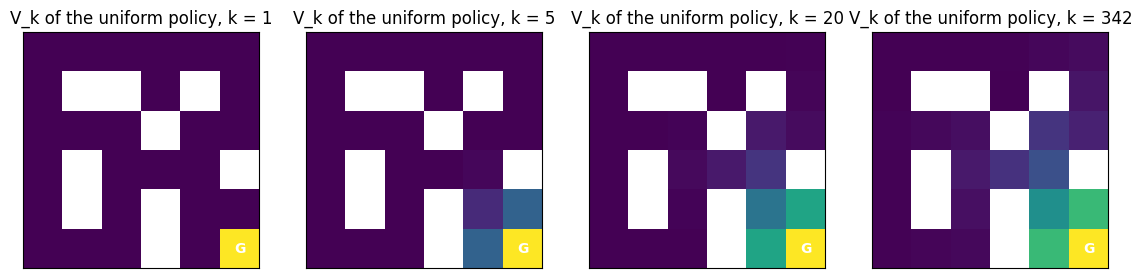

In [2]:
env = GridWorld(experiment_gridworld_dp.LAYOUT, slip=0.1, gamma=0.95)
print("\n".join(experiment_gridworld_dp.LAYOUT))   # the known map: S start, G goal, # wall

uniform = TabularPolicy.uniform(env.n_states, env.n_actions).table
evaluation = PolicyEvaluation(env)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, k in zip(axes, (1, 5, 20, None)):
    v_k, deltas = evaluation.run(uniform, n_sweeps=k)
    plot_grid_values(ax, env, v_k, f"V_k of the uniform policy, k = {len(deltas)}", annotate=False)
plt.show()

$$\pi'(s) \in \arg\max_a q_\pi(s,a). \tag{10}$$

$\arg\max$ returns **the action that achieves the largest value**, while $\max$ only returns the largest value itself. $\pi'(s)$ is the action of the new policy at $s$: choose the best action according to $q_\pi$ of the old policy. If several actions achieve the maximum, choose one according to a specified tie rule. Here $\pi'$ is written like a deterministic policy; this step changes the policy after we have the action-values to compare.

The policy improvement theorem says that greedy improves on the value of the old policy under the corresponding MDP conditions. If only an approximate value that has not converged is used, do not treat this theorem as a guarantee that every update is better.

> **Code.** `PolicyImprovement` computes $q_\pi$ by one-step lookahead on $V$ (Eq. 6) and takes the argmax with the rule "first maximizing action". One improvement of the uniform policy already improves the value of every state.

In [3]:
v_uniform, _ = evaluation.run(uniform)
improved = PolicyImprovement(env)(v_uniform)
v_improved, _ = evaluation.run(improved.table)
live = ~env.terminal
print("v_pi'(s) >= v_pi(s) in every state:", bool(np.all(v_improved[live] >= v_uniform[live] - 1e-9)))
print(f"V(start): uniform = {v_uniform[env.start_state]:.2f}, after one improvement = {v_improved[env.start_state]:.2f}")

v_pi'(s) >= v_pi(s) in every state: True
V(start): uniform = -19.80, after one improvement = -8.89


$$V_{k+1}(s) = \max_a\Big[\mathcal R^a_s + \gamma \sum_{s'} \mathcal P^a_{ss'} V_k(s')\Big]. \tag{11}$$

Unlike policy evaluation, at each state we do not average according to a fixed policy but choose the action with the largest backup. The value of round $k$ provides the prediction of the future; round $k+1$ combines it with the reward/model to improve the optimal estimate. **Does the max really know the future?** No: it only compares predictions based on $V_k$. Delayed reward is propagated backward through the backup rounds.

**Why does it converge?** With $\gamma < 1$, the Bellman operators are contractions in the max norm. One backup shrinks the distance between two value vectors by at most a factor $\gamma$. Repeated backups lead to the unique fixed point. The case $\gamma = 1$ needs the corresponding episodic/proper assumptions; do not take the contraction above as the proof.

> **Code.** `ValueIteration` puts the max inside the sweep. `contraction_ratios` divides consecutive $\|V_{k+1}-V_k\|_\infty$; every ratio stays below $\gamma$.

In [4]:
vi = ValueIteration(env).run()
ratios = contraction_ratios(vi.deltas)
print(f"value iteration: {vi.sweeps} sweeps; largest ratio = {ratios.max():.3f} <= gamma = {env.gamma}")

value iteration: 32 sweeps; largest ratio = 0.950 <= gamma = 0.95


**Generalized policy iteration (GPI).** Evaluation and improvement may not be complete before switching steps; what matters is that they both act on the value and the policy. GPI is a thinking model for many later methods, not an algorithm with a single update. [Sutton–Barto, §4.6]

> **Code.** `GeneralizedPolicyIteration(eval_sweeps=k)` does only $k$ evaluation sweeps before each improvement. $k = $ `None` is policy iteration; all of them end at the same values.

In [5]:
for k in (1, 3, 10, None):
    res = GeneralizedPolicyIteration(env, eval_sweeps=k).run()
    print(f"eval_sweeps={str(k):4s}: {res.improvements:3d} improvements, {res.sweeps:4d} sweeps, "
          f"max |V - V_VI| = {np.max(np.abs(res.v - vi.v)):.1e}")

eval_sweeps=1   :  32 improvements,   32 sweeps, max |V - V_VI| = 0.0e+00
eval_sweeps=3   :  13 improvements,   37 sweeps, max |V - V_VI| = 4.0e-09
eval_sweeps=10  :   6 improvements,   44 sweeps, max |V - V_VI| = 3.9e-09
eval_sweeps=None:   2 improvements,  375 sweeps, max |V - V_VI| = 7.6e-09


## 4. Example and pipeline

A deterministic MDP: at $u$, receive $4$ then terminal; at $s$, action $a$ receives $0$ then goes to $u$, action $b$ receives $2$ then terminal. $\gamma = 0.9$, $V_0 = 0$. First synchronous backup: $V_1(u) = 4, V_1(s) = 2$. Second: $V_2(s) = \max(3.6, 2) = 3.6$. Delayed reward propagates backward through two backups.

1. **Data:** Read the model and initialize the value.
2. **Learning:** Back up according to the policy or the max; policy iteration also has a greedy improvement step.
3. **Use and evaluation:** Extract the policy from the value and the model; evaluate the action chosen from model-based lookahead.

In [6]:
ex = lecture_example_mdp(gamma=0.9)
s, u = ex.state_index("s"), ex.state_index("u")
for k, v_k in enumerate(ValueIteration(ex).iterate(2)):
    print(f"V_{k}: V(u) = {v_k[u]:.1f}, V(s) = {v_k[s]:.1f}")
print("greedy action in s:", ex.action_names[int(ValueIteration(ex).run().policy.table[s].argmax())])

V_0: V(u) = 0.0, V(s) = 0.0
V_1: V(u) = 4.0, V(s) = 2.0
V_2: V(u) = 4.0, V(s) = 3.6
greedy action in s: a


## 5. Comparison, limits and applications

Policy iteration evaluates a policy and then improves it; value iteration uses the max directly in the backup. MC/TD in the next sections replace the expectation over the model with experience. Tabular DP can be expensive when the state/action space is large; this is a problem of representation and sweeps, distinct from the cost of collecting data. An illustrative application is planning grid navigation with a known map and transitions.

> **Code.** The full experiment compares the solvers on the grid and saves the figure and a JSON summary in `artifacts/01_foundations_tabular/lesson_03_dynamic_programming/`.

policy iteration             sweeps= 375 improvements=  2 V(start)=-8.895
value iteration              sweeps=  32 improvements=  0 V(start)=-8.895
GPI (k=3 eval sweeps)        sweeps=  37 improvements= 13 V(start)=-8.895
value iteration, in place    sweeps=  25 improvements=  0 V(start)=-8.895


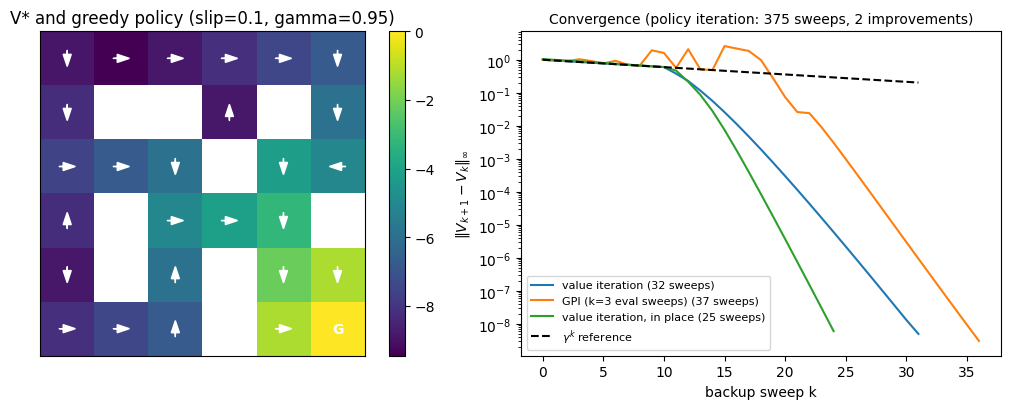

In [7]:
out = experiment_gridworld_dp.run(slip=0.1, gamma=0.95)
for name, row in out["summary"].items():
    if isinstance(row, dict):
        print(f"{name:28s} sweeps={row['sweeps']:4d} improvements={row['improvements']:3d} V(start)={row['V(start)']:.3f}")
plt.show()

## 6. Exercises

1. In the example, change $\gamma = 0.4$: does the final greedy policy choose $a$ or $b$?
2. If we update $u$ first and then use the new value for $s$ immediately within one sweep, does the result of round 1 differ from a synchronous backup?
3. Does contraction with a wrong model guarantee the correct policy in the real environment?

In [8]:
# Exercise 1
ex04 = lecture_example_mdp(gamma=0.4)
print("gamma = 0.4: q(s, .) =", ex04.lookahead(ValueIteration(ex04).run().v)[s].round(2),
      "-> greedy:", ex04.action_names[int(ValueIteration(ex04).run().policy.table[s].argmax())])
# Exercise 2: in place (u is listed before s) vs synchronous, round 1
print("round 1, synchronous V(s) =", ValueIteration(ex).iterate(1)[1][s],
      "| in place V(s) =", ValueIteration(ex, in_place=True).iterate(1)[1][s])
# Exercise 3: plan with a wrong model (u pays 1 instead of 4), act in the real one
wrong = lecture_example_mdp(gamma=0.9, u_reward=1.0)
plan = ValueIteration(wrong).run().policy.table
print("policy planned on the wrong model chooses", ex.action_names[int(plan[s].argmax())],
      f"-> real return {ex.evaluate_policy_exact(plan)[s]:.2f} vs optimal {ValueIteration(ex).run().v[s]:.2f}")

gamma = 0.4: q(s, .) = [1.6 2. ] -> greedy: b
round 1, synchronous V(s) = 2.0 | in place V(s) = 3.6
policy planned on the wrong model chooses b -> real return 2.00 vs optimal 3.60


<details>
<summary><b>Answers (Appendix A)</b></summary>

(1) Action $a$ gives $0.4\cdot 4 = 1.6$, $b$ gives $2$, so choose $b$. (2) Yes: an in-place sweep updates $u = 4$ then uses it immediately for $s$, giving $3.6$ within one sweep; the synchronous backup uses $V_0(u) = 0$. (3) No: the contraction of a wrong model only solves the fixed point of that model.
</details>

## 7. Remember and read further

DP needs a model; Bellman uses the model to back up; GPI links prediction with control. Read Silver 3 and Sutton–Barto §§4.1–4.6.